# ACA N° 1 – Aprendizaje Automático
## Diagnóstico asistido de cáncer de mama con Machine Learning clásico
**Corporación Unificada Nacional de Educación Superior (CUN)** · Escuela de Ingeniería · Especialización en Inteligencia Artificial
**Materia:** APRENDIZAJE AUTOMÁTICO/54ES1/SEGUNDO BLOQUE/26ES4 · **Formador:** Hamilton Rivera  
**Integrantes:** Duvan Daniel Gómez Alían, Jeisson Jesith Ortega Lozano, Dubier Alberto Quintero Gómez y Duberney Arboleda Luján · **Fecha:** 1 de noviembre de 2026
**Pilar:** 🩺 Salud · **Dataset:** UCI Breast Cancer Wisconsin (Diagnostic) — Wolberg, Street y Mangasarian (1995)

---

### Objetivo general
Desarrollar un modelo de Machine Learning clásico que clasifique tumores de mama como **benignos** o **malignos** a partir de 30 características numéricas extraídas de imágenes digitalizadas de una biopsia por aspiración con aguja fina (FNA), y desplegarlo en una aplicación interactiva de Streamlit.

### Pregunta orientadora
¿Cómo transformar las mediciones celulares de una biopsia en una predicción confiable del tipo de tumor, mediante técnicas clásicas de Machine Learning, y presentarla en una interfaz accesible para el personal de salud?

### Ruta de aprendizaje (estructura del notebook)
| Paso | Sección |
|---|---|
| 1 | Exploración y EDA |
| 2 | Limpieza y preparación de datos |
| 3 | Modelado clásico (comparación + ajuste de hiperparámetros) |
| 4 | Evaluación con métricas |
| 5 | Exportación del modelo para el despliegue en Streamlit |

> **Nota de reproducibilidad:** el dataset viene incluido en `scikit-learn` (`load_breast_cancer`), así que el notebook corre sin descargas externas. Se fija una semilla (`RANDOM_STATE = 42`) para que los resultados sean iguales en cada ejecución.

## 0. Configuración del entorno

In [1]:
# Librerías estándar y de análisis
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

# Scikit-learn: datos, preprocesamiento, modelos y métricas
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo de gráficos
sns.set_theme(style="whitegrid", context="notebook")
COLORES = {"Benigno": "#2a9d8f", "Maligno": "#e76f51"}

# Carpetas del proyecto (se crean si no existen)
BASE = Path("..") if Path.cwd().name == "notebook" else Path(".")
DIR_DATA, DIR_MODELS, DIR_FIG = BASE / "data", BASE / "models", BASE / "figures"
for d in (DIR_DATA, DIR_MODELS, DIR_FIG):
    d.mkdir(parents=True, exist_ok=True)

print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


# PASO 1 · Exploración y EDA
## 1.1 Carga de datos
Cada fila es una muestra de tejido. Para cada núcleo celular se midieron 10 rasgos (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), y para cada rasgo se reportan 3 estadísticos: **media**, **error estándar** y **peor valor** (promedio de los 3 valores más grandes). Eso da 3 × 10 = **30 variables predictoras**.

In [2]:
datos = load_breast_cancer(as_frame=True)
df = datos.frame.copy()

# En scikit-learn: 0 = maligno, 1 = benigno.
# Lo recodificamos para que la clase POSITIVA (1) sea la de interés clínico: maligno.
df["diagnostico"] = (df["target"] == 0).astype(int)   # 1 = Maligno, 0 = Benigno
df = df.drop(columns="target")

# Guardamos una copia en CSV para trazabilidad
df.to_csv(DIR_DATA / "breast_cancer_wisconsin.csv", index=False)

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 1.2 Estructura y tipos de datos

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [4]:
# Estadísticos descriptivos (transpuesto para leer mejor)
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


**Lectura:** las 30 variables son numéricas continuas (`float64`). Las escalas son muy distintas: por ejemplo `mean area` llega a valores de miles, mientras `mean fractal dimension` está alrededor de 0.06. Esto indica que habrá que **estandarizar** antes de usar modelos basados en distancias o en coeficientes (KNN, SVM, Regresión Logística).

## 1.3 Distribución de la variable objetivo

             casos     %
diagnostico             
Benigno        357  62.7
Maligno        212  37.3


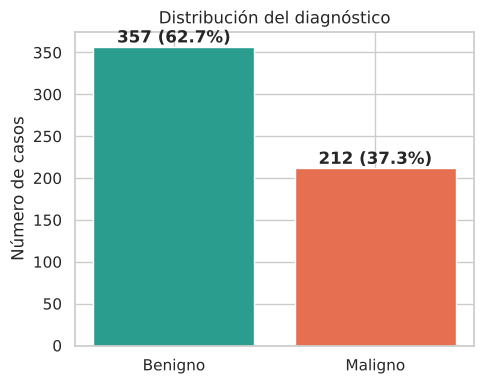

In [5]:
conteo = df["diagnostico"].map({0: "Benigno", 1: "Maligno"}).value_counts()
porc = (conteo / len(df) * 100).round(1)
print(pd.DataFrame({"casos": conteo, "%": porc}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
for i, (v, p) in enumerate(zip(conteo.values, porc.values)):
    ax.text(i, v + 5, f"{v} ({p}%)", ha="center", fontweight="bold")
ax.set_title("Distribución del diagnóstico")
ax.set_ylabel("Número de casos")
plt.tight_layout(); plt.savefig(DIR_FIG / "01_balance_clases.png", dpi=150); plt.show()

**Lectura:** hay un desbalance **moderado** (≈63 % benignos vs ≈37 % malignos). No es extremo, así que no hace falta sobremuestreo (SMOTE), pero sí debemos: (1) dividir los datos de forma **estratificada** y (2) no confiar solo en la exactitud (*accuracy*), sino priorizar **Recall** y **F1** de la clase maligna.

## 1.4 Distribución de las variables por clase

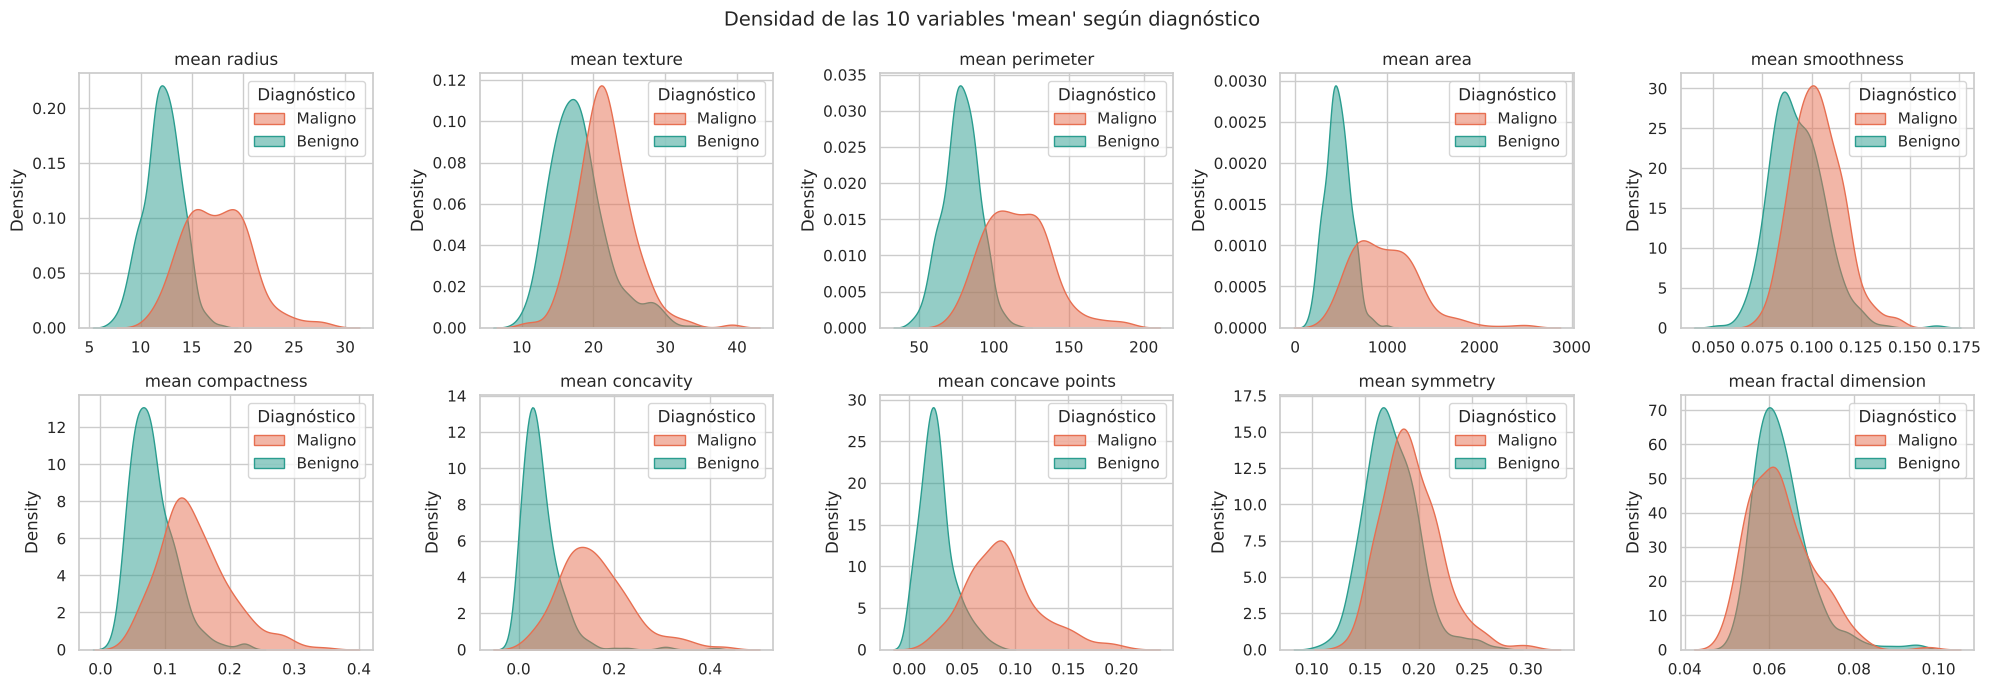

In [6]:
variables_media = [c for c in df.columns if c.startswith("mean")]
df_plot = df.assign(Diagnóstico=df["diagnostico"].map({0: "Benigno", 1: "Maligno"}))

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), variables_media):
    sns.kdeplot(data=df_plot, x=col, hue="Diagnóstico", fill=True,
                common_norm=False, palette=COLORES, ax=ax, alpha=0.5)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Densidad de las 10 variables 'mean' según diagnóstico", fontsize=14)
plt.tight_layout(); plt.savefig(DIR_FIG / "02_densidades.png", dpi=150); plt.show()

**Lectura:** variables como `mean radius`, `mean perimeter`, `mean area`, `mean concavity` y `mean concave points` separan muy bien las dos clases: los tumores malignos tienen células más grandes y con contornos más irregulares. En cambio, `mean fractal dimension` y `mean symmetry` se solapan mucho, por lo que aportan menos información por sí solas.

## 1.5 Correlaciones

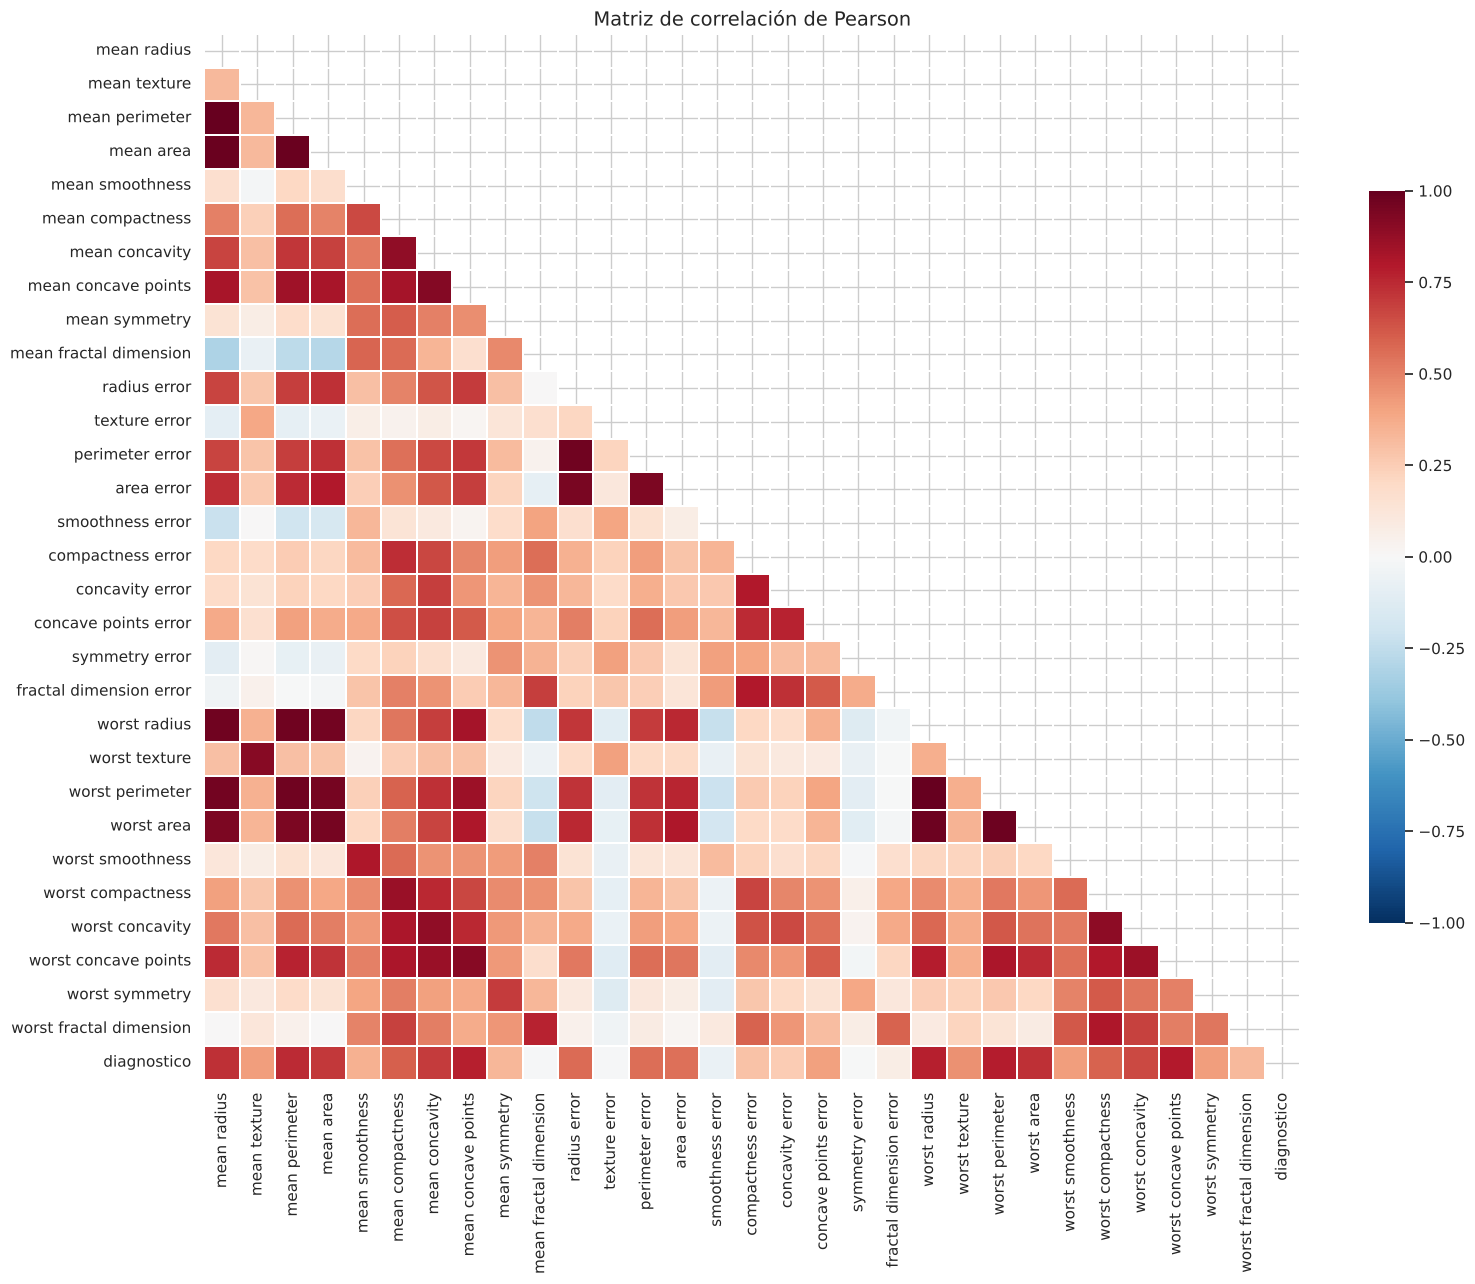

In [7]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matriz de correlación de Pearson", fontsize=14)
plt.tight_layout(); plt.savefig(DIR_FIG / "03_correlaciones.png", dpi=150); plt.show()

Variables más correlacionadas con 'maligno':
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660
Name: diagnostico, dtype: float64


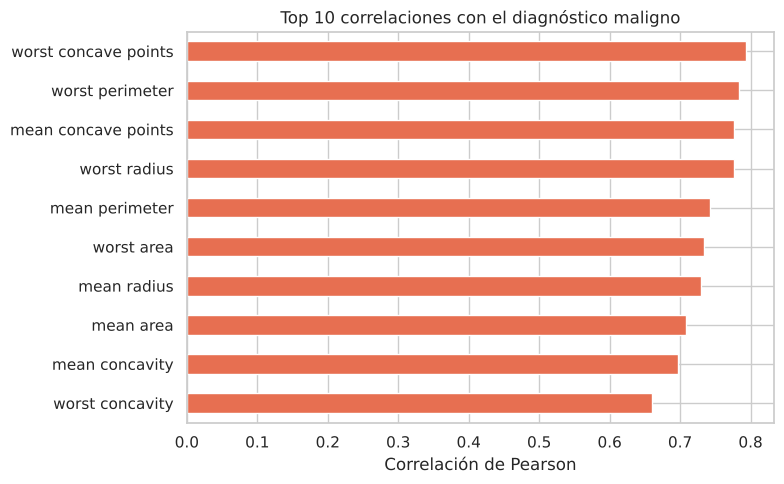

In [8]:
# Correlación de cada variable con el diagnóstico (top 10)
corr_obj = corr["diagnostico"].drop("diagnostico").sort_values(ascending=False)
print("Variables más correlacionadas con 'maligno':")
print(corr_obj.head(10).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
corr_obj.head(10).sort_values().plot.barh(color="#e76f51", ax=ax)
ax.set_title("Top 10 correlaciones con el diagnóstico maligno")
ax.set_xlabel("Correlación de Pearson")
plt.tight_layout(); plt.savefig(DIR_FIG / "04_corr_objetivo.png", dpi=150); plt.show()

**Lectura:** existe **alta multicolinealidad** entre radio, perímetro y área (son geométricamente dependientes: correlaciones > 0.95). Esto no afecta la capacidad predictiva de los modelos, pero sí la interpretación individual de los coeficientes. Lo manejamos con **regularización** (L1/L2) en la Regresión Logística en lugar de eliminar variables a mano.

# PASO 2 · Limpieza y preparación de datos
## 2.1 Valores faltantes y duplicados

In [9]:
nulos = df.isnull().sum().sum()
duplicados = df.duplicated().sum()
print(f"Valores nulos totales : {nulos}")
print(f"Filas duplicadas      : {duplicados}")

Valores nulos totales : 0
Filas duplicadas      : 0


**Resultado:** el dataset no tiene valores faltantes ni filas duplicadas, por lo que **no se requiere imputación**. Aun así, el `Pipeline` del modelo queda preparado para recibir datos nuevos (por ejemplo, desde la app) con el mismo formato.

## 2.2 Valores atípicos (outliers)

In [10]:
X_tmp = df.drop(columns="diagnostico")
Q1, Q3 = X_tmp.quantile(0.25), X_tmp.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X_tmp < Q1 - 1.5 * IQR) | (X_tmp > Q3 + 1.5 * IQR)).sum().sort_values(ascending=False)
print("Outliers por variable (regla 1.5·IQR), top 10:")
print(outliers.head(10))

filas_con_outlier = ((X_tmp < Q1 - 1.5 * IQR) | (X_tmp > Q3 + 1.5 * IQR)).any(axis=1)
print(f"\nFilas con al menos un outlier: {filas_con_outlier.sum()} de {len(df)}")
print("Distribución del diagnóstico en esas filas:")
print(df.loc[filas_con_outlier, "diagnostico"].map({0:"Benigno",1:"Maligno"}).value_counts())

Outliers por variable (regla 1.5·IQR), top 10:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64

Filas con al menos un outlier: 171 de 569
Distribución del diagnóstico en esas filas:
diagnostico
Maligno    114
Benigno     57
Name: count, dtype: int64


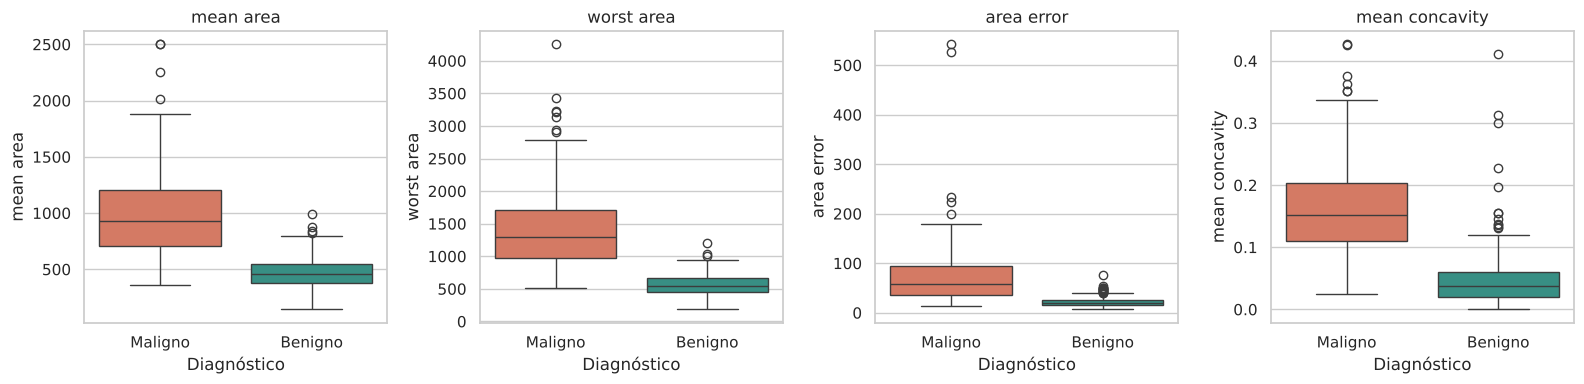

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["mean area", "worst area", "area error", "mean concavity"]):
    sns.boxplot(data=df_plot, x="Diagnóstico", y=col, palette=COLORES, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(DIR_FIG / "05_boxplots.png", dpi=150); plt.show()

**Decisión:** **no eliminamos** los outliers. Los boxplots muestran que la mayoría de valores extremos pertenecen a tumores **malignos**: no son errores de medición sino la señal clínica que queremos detectar. Eliminarlos sesgaría el modelo contra la clase de interés. Usamos `StandardScaler` dentro del pipeline y modelos robustos (Random Forest, SVM con regularización) para controlar su efecto.

## 2.3 División entrenamiento / prueba
Se separa el **20 %** de los datos como conjunto de prueba que **no se toca** hasta la evaluación final. La división es **estratificada** para conservar la proporción benigno/maligno en ambos conjuntos.

In [12]:
X = df.drop(columns="diagnostico")
y = df["diagnostico"]
FEATURES = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape}  | % maligno = {y_train.mean():.3f}")
print(f"Prueba       : {X_test.shape}  | % maligno = {y_test.mean():.3f}")

Entrenamiento: (455, 30)  | % maligno = 0.374
Prueba       : (114, 30)  | % maligno = 0.368


## 2.4 Estandarización dentro de un Pipeline
El escalado se incluye **dentro** de un `Pipeline` de scikit-learn. Así, en cada pliegue de la validación cruzada el `StandardScaler` se ajusta **solo** con los datos de entrenamiento de ese pliegue, evitando **fuga de información** (*data leakage*) hacia los datos de validación.

# PASO 3 · Modelado clásico
## 3.1 Comparación de 6 algoritmos con validación cruzada
Se comparan seis algoritmos clásicos con **validación cruzada estratificada de 5 pliegues** sobre el conjunto de entrenamiento:

| Algoritmo | Idea principal |
|---|---|
| Regresión Logística | Modelo lineal que estima la probabilidad de malignidad |
| KNN | Clasifica según los *k* casos más parecidos |
| SVM (RBF) | Busca la frontera de máximo margen, admite fronteras no lineales |
| Árbol de Decisión | Reglas *si-entonces* fáciles de interpretar |
| Random Forest | Ensamble de muchos árboles, reduce varianza |
| Naive Bayes Gaussiano | Modelo probabilístico simple, asume independencia |

In [13]:
def crear_pipeline(modelo):
    return Pipeline([("escalador", StandardScaler()), ("modelo", modelo)])

modelos = {
    "Regresión Logística": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(),
    "SVM (RBF)":           SVC(probability=True, random_state=RANDOM_STATE),
    "Árbol de Decisión":   DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(random_state=RANDOM_STATE),
    "Naive Bayes":         GaussianNB(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]

resultados = []
for nombre, modelo in modelos.items():
    scores = cross_validate(crear_pipeline(modelo), X_train, y_train,
                            cv=cv, scoring=metricas_cv)
    fila = {"Modelo": nombre}
    for m in metricas_cv:
        fila[m] = scores[f"test_{m}"].mean()
        fila[f"{m}_std"] = scores[f"test_{m}"].std()
    resultados.append(fila)

tabla_cv = (pd.DataFrame(resultados).set_index("Modelo")
            .sort_values("f1", ascending=False))
tabla_cv[metricas_cv].round(4)

,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,
Regresión Logística,0.9736,0.9771,0.9529,0.9640,0.9958
SVM (RBF),0.9714,0.9769,0.9471,0.9610,0.9949
Random Forest,0.9648,0.9641,0.9412,0.9519,0.9889
KNN,0.9648,0.9875,0.9176,0.9510,0.9871
Naive Bayes,0.9385,0.9247,0.9118,0.9170,0.9870
Árbol de Decisión,0.9231,0.8996,0.8941,0.8962,0.9172


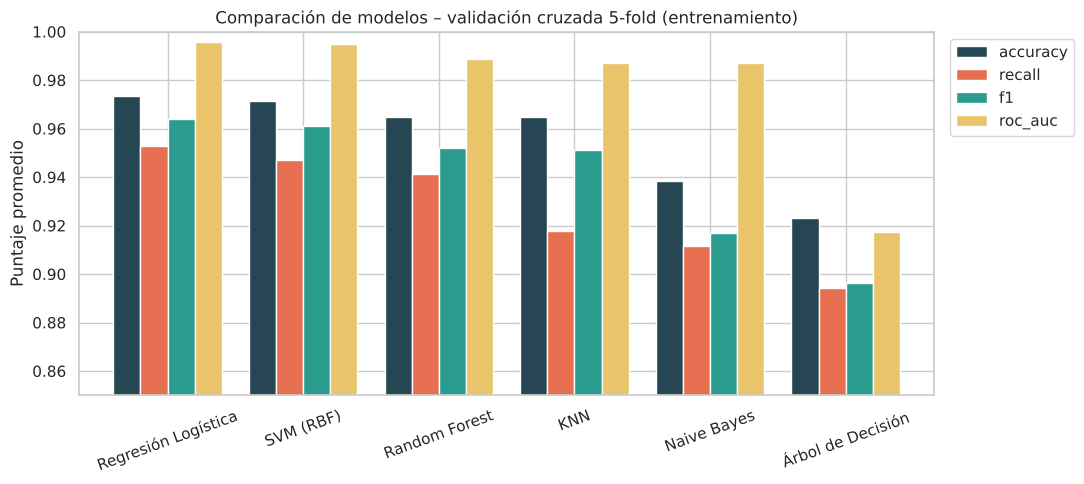

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
tabla_cv[["accuracy", "recall", "f1", "roc_auc"]].plot.bar(ax=ax, width=0.8,
        color=["#264653", "#e76f51", "#2a9d8f", "#e9c46a"])
ax.set_ylim(0.85, 1.0)
ax.set_title("Comparación de modelos – validación cruzada 5-fold (entrenamiento)")
ax.set_ylabel("Puntaje promedio"); ax.set_xlabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(DIR_FIG / "06_comparacion_modelos.png", dpi=150); plt.show()

**Lectura:** los modelos que trabajan con datos estandarizados (Regresión Logística y SVM) obtienen los mejores puntajes, con F1 y AUC cercanos a 0.97–0.99. El Árbol de Decisión individual es el más débil (se sobreajusta con facilidad) y Naive Bayes se ve afectado por la fuerte correlación entre variables, que rompe su supuesto de independencia.

Pasamos los **dos mejores candidatos** (Regresión Logística y SVM) a una búsqueda de hiperparámetros.

## 3.2 Ajuste de hiperparámetros (GridSearchCV)
Criterio de selección: **F1 de la clase maligna**, porque equilibra dos errores con costo clínico distinto:
- **Falso negativo** (decir benigno a un tumor maligno) → retrasa el tratamiento. Es el error más grave.
- **Falso positivo** (decir maligno a un benigno) → genera ansiedad y exámenes adicionales.

In [15]:
grids = {
    "Regresión Logística": (
        LogisticRegression(max_iter=5000, solver="liblinear", random_state=RANDOM_STATE),
        {"modelo__C": [0.01, 0.1, 0.5, 1, 5, 10, 50],
         "modelo__penalty": ["l1", "l2"],
         "modelo__class_weight": [None, "balanced"]}),
    "SVM (RBF)": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"modelo__C": [0.1, 1, 5, 10, 50],
         "modelo__gamma": ["scale", 0.001, 0.01, 0.05],
         "modelo__class_weight": [None, "balanced"]}),
}

busquedas = {}
for nombre, (modelo, grid) in grids.items():
    gs = GridSearchCV(crear_pipeline(modelo), grid, cv=cv,
                      scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
                      refit="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    i = gs.best_index_
    print(f"▶ {nombre}")
    print(f"   Mejores parámetros: {gs.best_params_}")
    print(f"   F1 CV = {gs.cv_results_['mean_test_f1'][i]:.4f} | "
          f"Recall CV = {gs.cv_results_['mean_test_recall'][i]:.4f} | "
          f"AUC CV = {gs.cv_results_['mean_test_roc_auc'][i]:.4f}\n")

▶ Regresión Logística
   Mejores parámetros: {'modelo__C': 0.1, 'modelo__class_weight': 'balanced', 'modelo__penalty': 'l2'}
   F1 CV = 0.9674 | Recall CV = 0.9588 | AUC CV = 0.9949



▶ SVM (RBF)
   Mejores parámetros: {'modelo__C': 5, 'modelo__class_weight': None, 'modelo__gamma': 'scale'}
   F1 CV = 0.9731 | Recall CV = 0.9647 | AUC CV = 0.9950



In [16]:
# Selección del modelo final según F1 en validación cruzada
nombre_final = max(busquedas, key=lambda k: busquedas[k].best_score_)
modelo_final = busquedas[nombre_final].best_estimator_
params_finales = busquedas[nombre_final].best_params_
print(f"✅ Modelo seleccionado: {nombre_final}")
print(f"   Parámetros: {params_finales}")

✅ Modelo seleccionado: SVM (RBF)
   Parámetros: {'modelo__C': 5, 'modelo__class_weight': None, 'modelo__gamma': 'scale'}


**Justificación técnica de la selección (SVM con kernel RBF, C = 5, gamma = 'scale'):**
1. **Mejor desempeño en validación cruzada:** obtuvo el F1 más alto (≈0.973) con el mayor Recall (≈0.965) entre los candidatos ajustados, superando ligeramente a la Regresión Logística.
2. **Frontera no lineal:** el kernel RBF permite separar clases cuya frontera no es una línea recta, algo que se intuye en las densidades del EDA donde las clases se solapan en algunas zonas.
3. **Robusto en alta dimensión y con multicolinealidad:** la SVM maximiza el margen y el parámetro `C` actúa como regularización, por lo que no necesita eliminar variables correlacionadas.
4. **Tamaño de datos adecuado:** con 569 muestras, la SVM entrena en milisegundos, lo que facilita el despliegue en Streamlit.
5. **Probabilidades:** con `probability=True` entrega una probabilidad de malignidad (calibración de Platt), que permite ajustar el umbral de decisión en la app.

La Regresión Logística queda como **alternativa interpretable** muy cercana en desempeño. Como la SVM-RBF no tiene coeficientes directos, su interpretabilidad se obtiene con **importancia por permutación** (sección 4.5).

# PASO 4 · Evaluación con métricas
## 4.1 Desempeño en el conjunto de prueba (datos nunca vistos)

In [17]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

metricas_test = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_proba),
}
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
metricas_test["Especificidad"] = tn / (tn + fp)

pd.Series(metricas_test, name=nombre_final).to_frame().round(4)

,SVM (RBF)
Accuracy,0.9737
Precision,1.0000
Recall,0.9286
F1-score,0.9630
ROC-AUC,0.9947
Especificidad,1.0000


In [18]:
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"], digits=4))

              precision    recall  f1-score   support

     Benigno     0.9600    1.0000    0.9796        72
     Maligno     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



## 4.2 Matriz de confusión

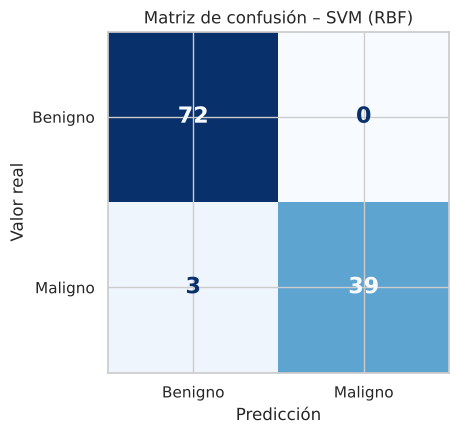

Verdaderos negativos (benigno bien clasificado) : 72
Falsos positivos   (benigno marcado maligno)    : 0
Falsos negativos   (maligno marcado benigno)    : 3
Verdaderos positivos (maligno detectado)        : 39


In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Benigno", "Maligno"],
    cmap="Blues", colorbar=False, ax=ax, text_kw={"fontsize": 16, "fontweight": "bold"})
ax.set_title(f"Matriz de confusión – {nombre_final}")
ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
plt.tight_layout(); plt.savefig(DIR_FIG / "07_matriz_confusion.png", dpi=150); plt.show()

print(f"Verdaderos negativos (benigno bien clasificado) : {tn}")
print(f"Falsos positivos   (benigno marcado maligno)    : {fp}")
print(f"Falsos negativos   (maligno marcado benigno)    : {fn}")
print(f"Verdaderos positivos (maligno detectado)        : {tp}")

## 4.3 Curva ROC

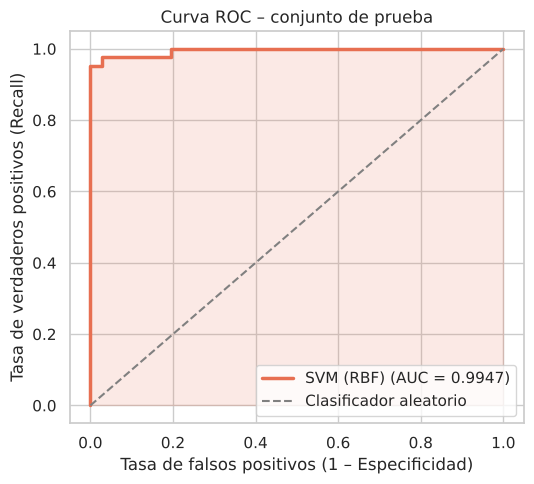

In [20]:
fpr, tpr, umbrales = roc_curve(y_test, y_proba)
auc = metricas_test["ROC-AUC"]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#e76f51", lw=2.5, label=f"{nombre_final} (AUC = {auc:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Clasificador aleatorio")
ax.fill_between(fpr, tpr, alpha=0.15, color="#e76f51")
ax.set_xlabel("Tasa de falsos positivos (1 – Especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curva ROC – conjunto de prueba"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(DIR_FIG / "08_curva_roc.png", dpi=150); plt.show()

## 4.4 Análisis del umbral de decisión
Por defecto el modelo clasifica como maligno cuando la probabilidad es ≥ 0.50. En un tamizaje clínico se puede **bajar el umbral** para detectar más malignos, a cambio de algunos falsos positivos adicionales. Esta tabla muestra ese compromiso.

In [21]:
filas = []
for u in [0.20, 0.30, 0.40, 0.50, 0.60]:
    p = (y_proba >= u).astype(int)
    tn_u, fp_u, fn_u, tp_u = confusion_matrix(y_test, p).ravel()
    filas.append({"Umbral": u, "Recall": recall_score(y_test, p),
                  "Precision": precision_score(y_test, p), "F1": f1_score(y_test, p),
                  "Falsos negativos": fn_u, "Falsos positivos": fp_u})
tabla_umbral = pd.DataFrame(filas).set_index("Umbral")
tabla_umbral.round(4)

,Recall,Precision,F1,Falsos negativos,Falsos positivos
Umbral,,,,,
0.2,0.9762,0.9111,0.9425,1,4
0.3,0.9762,0.9535,0.9647,1,2
0.4,0.9524,1.0000,0.9756,2,0
0.5,0.9286,1.0000,0.9630,3,0
0.6,0.9286,1.0000,0.9630,3,0


**Lectura:** bajar el umbral reduce los falsos negativos (el error más costoso) con un aumento moderado de falsos positivos. En la app de Streamlit el usuario puede mover este umbral con un control deslizante para ver el efecto en tiempo real.

## 4.5 Interpretabilidad: ¿qué variables pesan más?

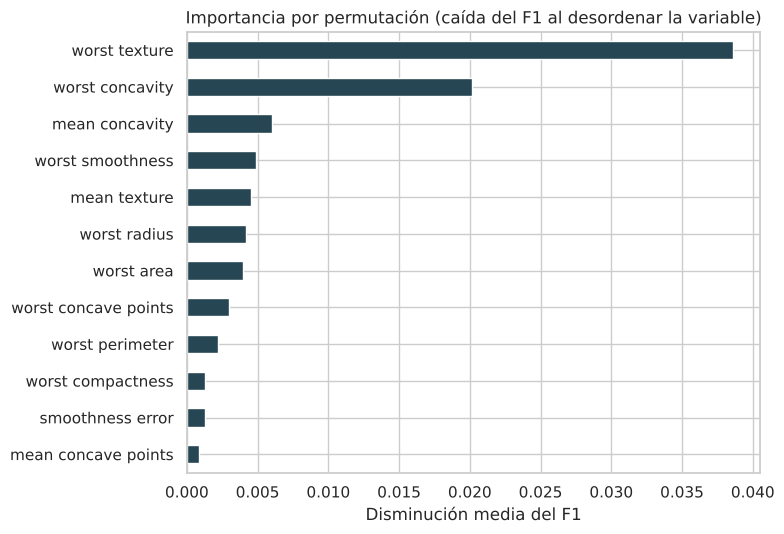

worst texture           0.0386
worst concavity         0.0201
mean concavity          0.0060
worst smoothness        0.0049
mean texture            0.0046
worst radius            0.0042
worst area              0.0040
worst concave points    0.0029
worst perimeter         0.0022
worst compactness       0.0013
dtype: float64

In [22]:
imp = permutation_importance(modelo_final, X_test, y_test, scoring="f1",
                             n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
importancias = (pd.Series(imp.importances_mean, index=FEATURES)
                .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 5.5))
importancias.head(12).sort_values().plot.barh(color="#264653", ax=ax)
ax.set_title("Importancia por permutación (caída del F1 al desordenar la variable)")
ax.set_xlabel("Disminución media del F1")
plt.tight_layout(); plt.savefig(DIR_FIG / "09_importancia.png", dpi=150); plt.show()
importancias.head(10).round(4)

In [23]:
# Si el modelo final es lineal, mostramos también los coeficientes estandarizados
clf = modelo_final.named_steps["modelo"]
if hasattr(clf, "coef_"):
    coef = pd.Series(clf.coef_[0], index=FEATURES)
    coef = coef[coef != 0].sort_values()
    print(f"Variables con coeficiente distinto de 0: {len(coef)} de {len(FEATURES)}")
    fig, ax = plt.subplots(figsize=(8, max(4, len(coef) * 0.28)))
    coef.plot.barh(color=np.where(coef > 0, "#e76f51", "#2a9d8f"), ax=ax)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title("Coeficientes de la Regresión Logística (datos estandarizados)\n"
                 "Rojo = aumenta probabilidad de maligno · Verde = la reduce")
    plt.tight_layout(); plt.savefig(DIR_FIG / "10_coeficientes.png", dpi=150); plt.show()
else:
    print("El modelo final no es lineal: se usa solo la importancia por permutación.")

El modelo final no es lineal: se usa solo la importancia por permutación.


## 4.6 Verificación de sobreajuste
Comparamos el desempeño en entrenamiento, validación cruzada y prueba. Si las tres cifras son cercanas, el modelo **generaliza** bien.

In [24]:
f1_train = f1_score(y_train, modelo_final.predict(X_train))
f1_cv = busquedas[nombre_final].best_score_
f1_test = metricas_test["F1-score"]
pd.DataFrame({"F1": [f1_train, f1_cv, f1_test]},
             index=["Entrenamiento", "Validación cruzada", "Prueba"]).round(4)

,F1
Entrenamiento,0.9851
Validación cruzada,0.9731
Prueba,0.9630


# PASO 5 · Exportación del modelo para Streamlit
Se guarda el **pipeline completo** (escalador + modelo) con `joblib`, junto con un archivo `metadata.json` con la información que necesita la app: nombres de variables, rangos para los controles deslizantes, métricas y matriz de confusión.

In [25]:
joblib.dump(modelo_final, DIR_MODELS / "modelo_cancer_mama.joblib")

metadata = {
    "modelo": nombre_final,
    "parametros": {k.replace("modelo__", ""): (v if v is not None else "None")
                   for k, v in params_finales.items()},
    "features": FEATURES,
    "rangos": {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                   "mediana": float(X[c].median()),
                   "mediana_benigno": float(X.loc[y == 0, c].median()),
                   "mediana_maligno": float(X.loc[y == 1, c].median())}
               for c in FEATURES},
    "metricas_test": {k: round(float(v), 4) for k, v in metricas_test.items()},
    "metricas_cv": tabla_cv[metricas_cv].round(4).to_dict(orient="index"),
    "matriz_confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "roc": {"fpr": fpr.round(4).tolist(), "tpr": tpr.round(4).tolist()},
    "umbral": tabla_umbral.round(4).reset_index().to_dict(orient="records"),
    "importancias": importancias.round(5).to_dict(),
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "sklearn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
}
with open(DIR_MODELS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Archivo de ejemplo para probar la predicción por lotes en la app
X_test.head(10).to_csv(DIR_DATA / "ejemplo_pacientes.csv", index=False)

# Prueba rápida: recargar el modelo y predecir
cargado = joblib.load(DIR_MODELS / "modelo_cancer_mama.joblib")
assert (cargado.predict(X_test) == y_pred).all()
print("✅ Modelo y metadatos guardados y verificados en", DIR_MODELS.resolve())

✅ Modelo y metadatos guardados y verificados en /home/claude/proyecto/models


# Conclusiones
1. **Calidad de datos:** el dataset no presentó nulos ni duplicados. Los outliers se conservaron porque representan la señal clínica de malignidad. El escalado se hizo dentro de un `Pipeline` para evitar fuga de información.
2. **Modelo:** de seis algoritmos clásicos comparados con validación cruzada estratificada, Regresión Logística y SVM fueron los mejores. Tras un `GridSearchCV` optimizando F1, se seleccionó **SVM con kernel RBF (C = 5)**.
3. **Métricas:** en datos nunca vistos el modelo alcanza **Accuracy ≈ 97.4 %, Precision = 100 %, Recall ≈ 92.9 %, F1 ≈ 0.963 y ROC-AUC ≈ 0.99**. No hubo falsos positivos y solo 3 de 42 malignos se clasificaron como benignos. El F1 es similar en entrenamiento (0.985), validación (0.973) y prueba (0.963), lo que indica **un sobreajuste mínimo**.
4. **Umbral clínico:** bajar el umbral de 0.50 a 0.30 reduce los falsos negativos de 3 a 1 a cambio de solo 2 falsos positivos; para tamizaje se recomienda un umbral más bajo (validándolo con datos nuevos, ya que aquí se exploró sobre el conjunto de prueba).
5. **Interpretación clínica:** las variables de textura, concavidad y tamaño del núcleo (sobre todo sus valores `worst`) son las que más influyen en la predicción, lo cual es coherente con la literatura médica: los núcleos malignos son más grandes, irregulares y heterogéneos.
6. **Limitaciones:** 569 muestras de una sola institución; el modelo es una **herramienta de apoyo** y no reemplaza el diagnóstico histopatológico ni el criterio médico.

# Referencias (APA 7)
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. En *Biomedical Image Processing and Biomedical Visualization* (Vol. 1905, pp. 861–870). SPIE. https://doi.org/10.1117/12.148698
- Wolberg, W., Street, N., & Mangasarian, O. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic